In [1]:
from google.colab import files

uploaded = files.upload()

Saving drive-download-20261114T014248Z-1-002.zip to drive-download-20261114T014248Z-1-002.zip
Saving drive-download-20261114T014248Z-1-001(1).zip to drive-download-20261114T014248Z-1-001(1).zip


In [2]:
import zipfile
import glob
import os

zip_files = glob.glob("/content/*.zip")

os.makedirs("/content/flight_data", exist_ok=True)

for zip_path in zip_files:
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("/content/flight_data")

csv_files = glob.glob("/content/flight_data/**/*.csv", recursive=True)

print("CSV files:", len(csv_files))

CSV files: 12


## 1. Data Cleaning and Quality Checks
### 1.1 Load and Combine Monthly Flight Data

In [3]:
import pandas as pd
import glob
import os

# Locate all monthly CSV files
csv_files = sorted(glob.glob(
    "/content/flight_data/**/*.csv",
    recursive=True
))

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))

Number of CSV files: 12
2025_August.csv
2025_December.csv
2025_July.csv
2025_June.csv
2025_November.csv
2025_October.csv
2025_September.csv
2026_April.csv
2026_February.csv
2026_January.csv
2026_March.csv
2026_May.csv


### 1.2 Missing Value and Duplicate Record Analysis

In [4]:
# Select relevant columns
columns = [
    "FL_DATE",
    "OP_UNIQUE_CARRIER",
    "OP_CARRIER_FL_NUM",
    "ORIGIN",
    "DEST",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "CANCELLED",
    "DIVERTED",
    "ARR_DELAY",
    "ARR_DEL15"
]

# Combine all 12 monthly datasets
df = pd.concat(
    [
        pd.read_csv(file, usecols=columns, low_memory=False)
        for file in csv_files
    ],
    ignore_index=True
)

print("Original Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate flight records
flight_keys = [
    "FL_DATE",
    "OP_UNIQUE_CARRIER",
    "OP_CARRIER_FL_NUM",
    "ORIGIN",
    "DEST",
    "CRS_DEP_TIME"
]

print("\nDuplicate Flight Records:")
print(df.duplicated(subset=flight_keys).sum())

Original Dataset Shape: (7047314, 13)

Missing Values:
FL_DATE                   0
OP_UNIQUE_CARRIER         0
OP_CARRIER_FL_NUM         0
ORIGIN                    0
DEST                      0
CRS_DEP_TIME              0
CRS_ARR_TIME              0
ARR_DELAY            146754
ARR_DEL15            146754
CANCELLED                 0
DIVERTED                  0
CRS_ELAPSED_TIME          3
DISTANCE                  0
dtype: int64

Duplicate Flight Records:
0


### 1.3 Data Cleaning and Target Variable Preparation

In [5]:
# Exclude canceled and diverted flights
# Remove observations without a valid target
df_clean = df[
    (df["CANCELLED"] == 0) &
    (df["DIVERTED"] == 0) &
    (df["ARR_DEL15"].isin([0, 1]))
].copy()

# Convert the target variable to integer
df_clean["ARR_DEL15"] = df_clean["ARR_DEL15"].astype(int)

# Remove records missing essential predictors
required_features = [
    "FL_DATE",
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME",
    "DISTANCE"
]

df_clean = df_clean.dropna(subset=required_features)

# Display cleaning summary
print("Original Records:", len(df))
print("Cleaned Records:", len(df_clean))
print("Removed Records:", len(df) - len(df_clean))

print("\nArrival Delay Distribution:")
print(df_clean["ARR_DEL15"].value_counts())

print("\nArrival Delay Rate:")
print(f"{df_clean['ARR_DEL15'].mean() * 100:.2f}%")

Original Records: 7047314
Cleaned Records: 6900559
Removed Records: 146755

Arrival Delay Distribution:
ARR_DEL15
0    5338144
1    1562415
Name: count, dtype: int64

Arrival Delay Rate:
22.64%


### 1.4 Export the Cleaned Dataset

In [6]:
# Save the cleaned dataset for subsequent analysis
output_path = "/content/CIS508_Cleaned_Flights.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully.")
print("File location:", output_path)

Cleaned dataset saved successfully.
File location: /content/CIS508_Cleaned_Flights.csv


## 2. Exploratory Data Analysis (EDA) and Feature Engineering

Analyze arrival-delay patterns across time, airlines, and airports, then prepare leakage-safe features for machine learning.

### 2.1 Overall Arrival Delay Distribution

Examine the distribution of on-time and delayed flights to understand the target variable and class imbalance.

,Flight Count,Percentage (%)
On-Time (<15 min delay),5338144,77.36
Delayed (15+ min),1562415,22.64


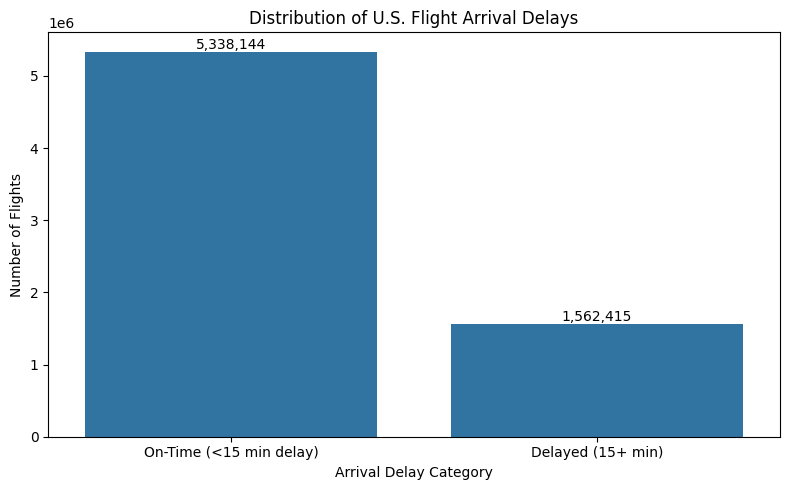

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate target distribution
delay_counts = df_clean["ARR_DEL15"].value_counts().sort_index()
delay_percentages = df_clean["ARR_DEL15"].value_counts(
    normalize=True
).sort_index() * 100

summary = pd.DataFrame({
    "Flight Count": delay_counts,
    "Percentage (%)": delay_percentages.round(2)
})

summary.index = ["On-Time (<15 min delay)", "Delayed (15+ min)"]

display(summary)

# Visualize arrival delay distribution
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=summary.index,
    y=summary["Flight Count"]
)

for i, count in enumerate(summary["Flight Count"]):
    ax.text(i, count, f"{count:,}", ha="center", va="bottom")

plt.title("Distribution of U.S. Flight Arrival Delays")
plt.xlabel("Arrival Delay Category")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

### 2.2 Monthly Arrival Delay Trends

Analyze monthly changes in arrival delay rates to identify seasonal patterns and temporal variation.

/tmp/ipykernel_459/3947525937.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_clean["FL_DATE"] = pd.to_datetime(df_clean["FL_DATE"])


,YEAR_MONTH,count,Delay Rate (%)
0,2025-06,599472,28.26
1,2025-07,612811,28.89
2,2025-08,593733,22.56
3,2025-09,558328,16.63
4,2025-10,601570,20.32
5,2025-11,555296,20.56
6,2025-12,571924,26.77
7,2026-01,517222,20.78
8,2026-02,502396,19.76
9,2026-03,592255,24.32


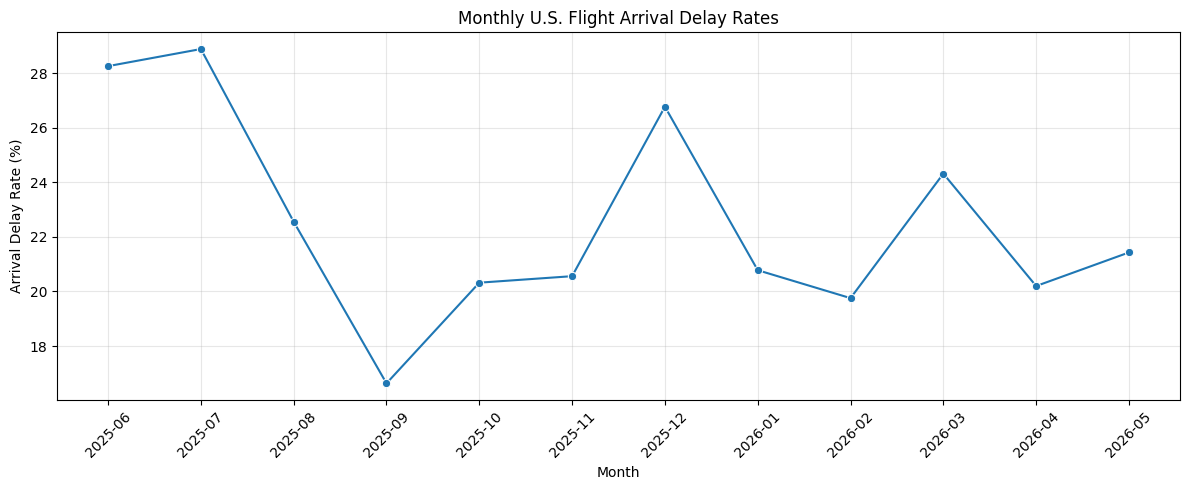

In [8]:
# Convert flight date to datetime
df_clean["FL_DATE"] = pd.to_datetime(df_clean["FL_DATE"])

# Create year-month feature
df_clean["YEAR_MONTH"] = df_clean["FL_DATE"].dt.to_period("M").astype(str)

# Calculate monthly arrival delay statistics
monthly_delay = (
    df_clean.groupby("YEAR_MONTH")["ARR_DEL15"]
    .agg(["count", "mean"])
    .reset_index()
)

monthly_delay["Delay Rate (%)"] = monthly_delay["mean"] * 100

display(monthly_delay[[
    "YEAR_MONTH", "count", "Delay Rate (%)"
]].round(2))

# Plot monthly delay rates
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_delay,
    x="YEAR_MONTH",
    y="Delay Rate (%)",
    marker="o"
)

plt.title("Monthly U.S. Flight Arrival Delay Rates")
plt.xlabel("Month")
plt.ylabel("Arrival Delay Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.3 Arrival Delay by Airline

Compare arrival delay rates across airlines to identify differences in operational performance.

,OP_UNIQUE_CARRIER,count,Delay Rate (%)
2,B6,226006,27.57
4,F9,198019,27.53
8,NK,146552,26.66
9,OH,231050,26.13
5,G4,127062,25.88
0,AA,959491,25.82
12,WN,1376351,22.92
13,YX,343736,22.13
1,AS,281510,21.81
10,OO,835522,21.26


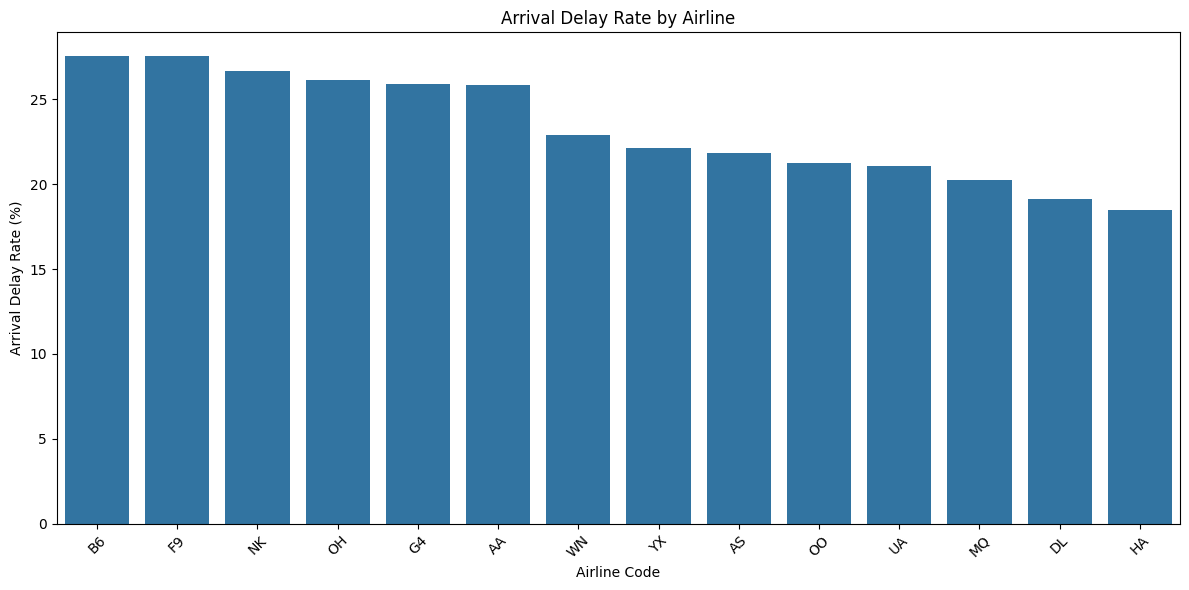

In [9]:
# Calculate airline delay statistics
airline_delay = (
    df_clean.groupby("OP_UNIQUE_CARRIER")["ARR_DEL15"]
    .agg(["count", "mean"])
    .reset_index()
)

airline_delay["Delay Rate (%)"] = airline_delay["mean"] * 100

airline_delay = airline_delay.sort_values(
    "Delay Rate (%)", ascending=False
)

display(airline_delay[[
    "OP_UNIQUE_CARRIER", "count", "Delay Rate (%)"
]].round(2))

# Plot arrival delay rate by airline
plt.figure(figsize=(12, 6))

sns.barplot(
    data=airline_delay,
    x="OP_UNIQUE_CARRIER",
    y="Delay Rate (%)"
)

plt.title("Arrival Delay Rate by Airline")
plt.xlabel("Airline Code")
plt.ylabel("Arrival Delay Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 2.4 Arrival Delay by Origin and Destination Airport

Compare arrival delay rates across departure and arrival airports. Only airports with at least 1,000 flights are included to reduce instability from small sample sizes.

Top 10 Origin Airports by Arrival Delay Rate:


,ORIGIN,count,mean,Delay Rate (%)
290,RST,1281,0.31,31.30
193,LCK,1144,0.31,30.94
63,CHO,1613,0.31,30.63
19,ASE,7452,0.31,30.53
304,SFB,10106,0.30,30.47
341,TVC,5145,0.30,29.89
103,EGE,3869,0.29,29.39
244,ORD,345808,0.29,29.24
217,MGM,1707,0.29,28.82
122,FNT,3660,0.29,28.72


Top 10 Destination Airports by Arrival Delay Rate:


,DEST,count,mean,Delay Rate (%)
304,SFB,10110,0.36,36.14
290,RST,1282,0.32,32.22
122,FNT,3668,0.32,31.92
260,PIE,9022,0.32,31.84
316,SLN,1047,0.31,31.33
80,CRW,2599,0.31,31.17
63,CHO,1630,0.31,30.92
200,LNK,3052,0.31,30.87
59,CAK,4557,0.31,30.59
47,BQN,2166,0.30,30.19


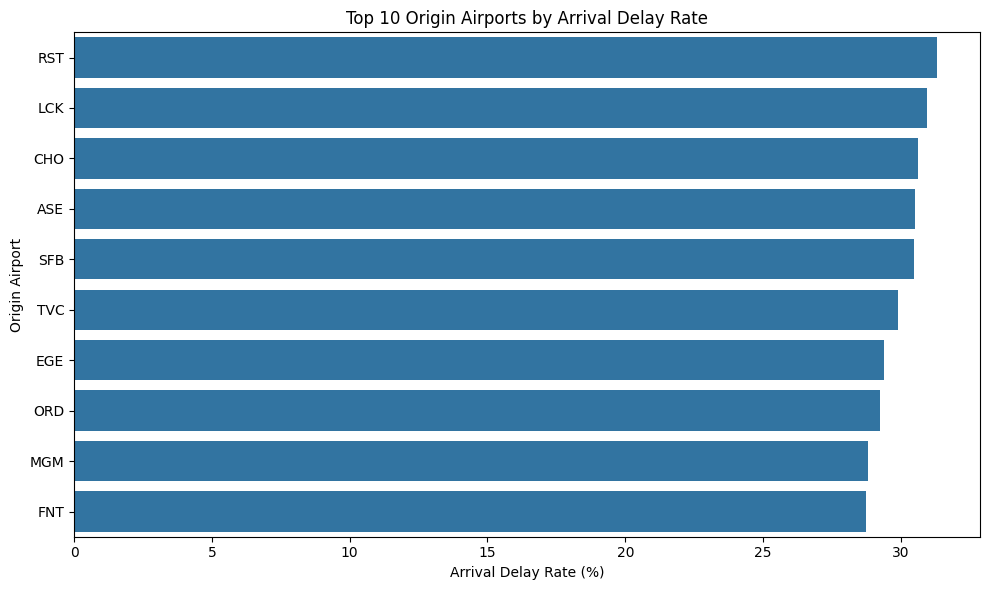

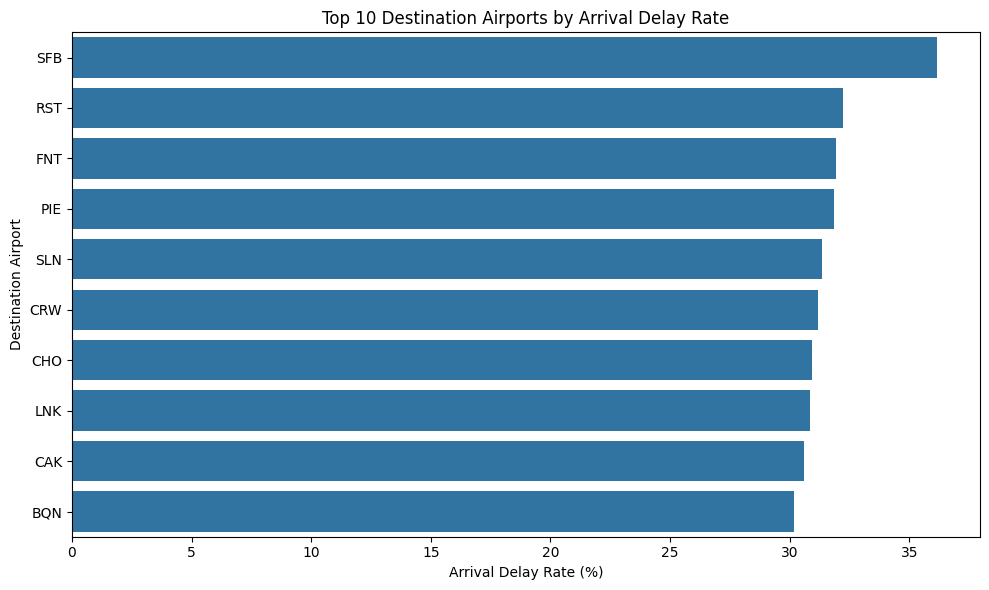

In [10]:
# Calculate delay statistics by origin airport
origin_delay = (
    df_clean.groupby("ORIGIN")["ARR_DEL15"]
    .agg(["count", "mean"])
    .reset_index()
)

origin_delay["Delay Rate (%)"] = origin_delay["mean"] * 100

# Filter airports with at least 1,000 flights
origin_delay = origin_delay[
    origin_delay["count"] >= 1000
].sort_values("Delay Rate (%)", ascending=False)

# Calculate delay statistics by destination airport
dest_delay = (
    df_clean.groupby("DEST")["ARR_DEL15"]
    .agg(["count", "mean"])
    .reset_index()
)

dest_delay["Delay Rate (%)"] = dest_delay["mean"] * 100

dest_delay = dest_delay[
    dest_delay["count"] >= 1000
].sort_values("Delay Rate (%)", ascending=False)

print("Top 10 Origin Airports by Arrival Delay Rate:")
display(origin_delay.head(10).round(2))

print("Top 10 Destination Airports by Arrival Delay Rate:")
display(dest_delay.head(10).round(2))

# Plot top 10 origin airports
plt.figure(figsize=(10, 6))

sns.barplot(
    data=origin_delay.head(10),
    x="Delay Rate (%)",
    y="ORIGIN"
)

plt.title("Top 10 Origin Airports by Arrival Delay Rate")
plt.xlabel("Arrival Delay Rate (%)")
plt.ylabel("Origin Airport")
plt.tight_layout()
plt.show()

# Plot top 10 destination airports
plt.figure(figsize=(10, 6))

sns.barplot(
    data=dest_delay.head(10),
    x="Delay Rate (%)",
    y="DEST"
)

plt.title("Top 10 Destination Airports by Arrival Delay Rate")
plt.xlabel("Arrival Delay Rate (%)")
plt.ylabel("Destination Airport")
plt.tight_layout()
plt.show()

### 2.5 Arrival Delay by Day of Week and Departure Hour

Examine how arrival delay rates vary by day of the week and scheduled departure hour to identify potential temporal patterns.

,Day,count,Delay Rate (%)
0,Monday,1028242,23.92
1,Tuesday,933018,19.19
2,Wednesday,942013,19.61
3,Thursday,1028827,23.28
4,Friday,1032966,23.67
5,Saturday,892914,21.49
6,Sunday,1042579,26.55


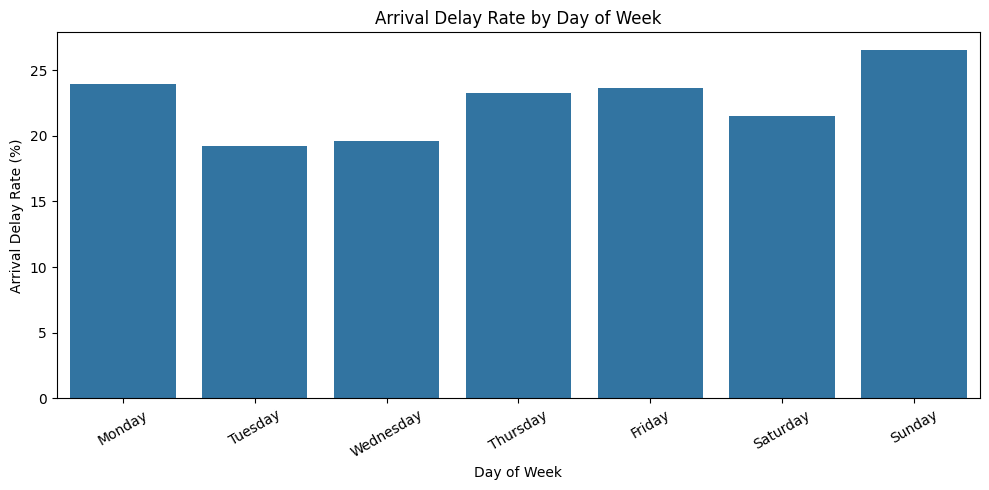

,DEP_HOUR,count,mean,Delay Rate (%)
0,0,10782,0.17,17.07
1,1,3405,0.19,19.03
2,2,1347,0.22,21.90
3,3,653,0.20,20.21
4,4,140,0.16,16.43
5,5,190225,0.08,8.33
6,6,474315,0.10,9.92
7,7,510360,0.13,12.58
8,8,479533,0.15,14.52
9,9,392614,0.16,16.21


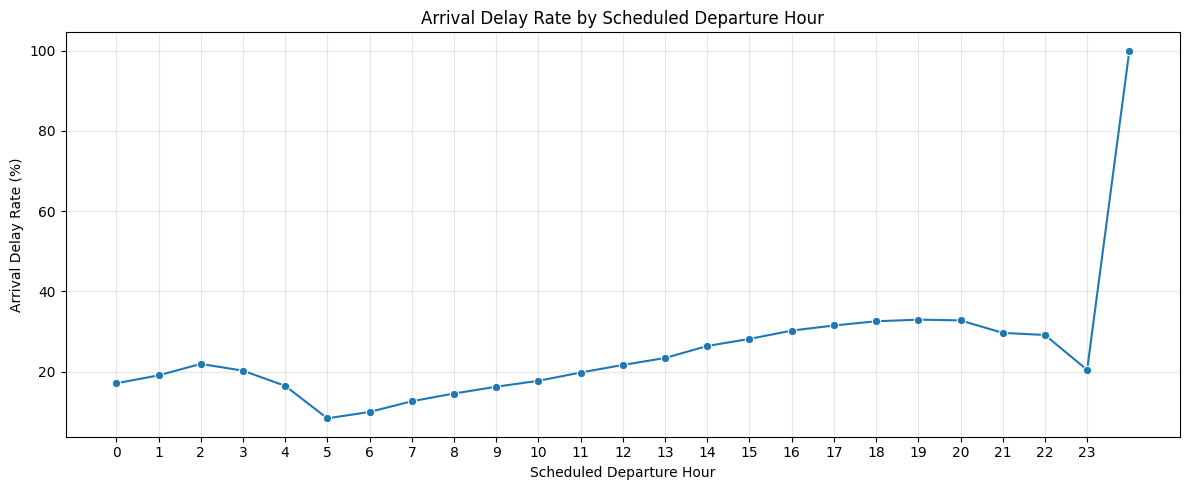

In [11]:
# Create calendar and scheduled departure hour features
df_clean["DAY_OF_WEEK"] = df_clean["FL_DATE"].dt.dayofweek

df_clean["DEP_HOUR"] = (
    df_clean["CRS_DEP_TIME"].astype(int) // 100
)

# Calculate arrival delay rate by day of week
day_delay = (
    df_clean.groupby("DAY_OF_WEEK")["ARR_DEL15"]
    .agg(["count", "mean"])
    .reset_index()
)

day_delay["Delay Rate (%)"] = day_delay["mean"] * 100

day_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_delay["Day"] = day_delay["DAY_OF_WEEK"].map(
    dict(enumerate(day_names))
)

display(day_delay[["Day", "count", "Delay Rate (%)"]].round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=day_delay,
    x="Day",
    y="Delay Rate (%)",
    order=day_names
)

plt.title("Arrival Delay Rate by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Arrival Delay Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Calculate arrival delay rate by scheduled departure hour
hour_delay = (
    df_clean.groupby("DEP_HOUR")["ARR_DEL15"]
    .agg(["count", "mean"])
    .reset_index()
)

hour_delay["Delay Rate (%)"] = hour_delay["mean"] * 100

display(hour_delay.round(2))

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hour_delay,
    x="DEP_HOUR",
    y="Delay Rate (%)",
    marker="o"
)

plt.title("Arrival Delay Rate by Scheduled Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Arrival Delay Rate (%)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.6 Feature Engineering and Data Leakage Prevention

Prepare predeparture features for machine learning while preventing data leakage. Only information available before flight departure will be used as model predictors. Actual arrival delay, departure delay, actual flight duration, and postdeparture operational outcomes will not be included as input features.

In [12]:
# Create calendar features
df_clean["MONTH"] = df_clean["FL_DATE"].dt.month
df_clean["DAY_OF_MONTH"] = df_clean["FL_DATE"].dt.day
df_clean["DAY_OF_WEEK"] = df_clean["FL_DATE"].dt.dayofweek

# Create scheduled time features
df_clean["DEP_HOUR"] = (
    df_clean["CRS_DEP_TIME"].astype(int) // 100
)

df_clean["ARR_HOUR"] = (
    df_clean["CRS_ARR_TIME"].astype(int) // 100
)

# Define predeparture predictors
feature_columns = [
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST",
    "MONTH",
    "DAY_OF_MONTH",
    "DAY_OF_WEEK",
    "DEP_HOUR",
    "ARR_HOUR",
    "CRS_ELAPSED_TIME",
    "DISTANCE"
]

target_column = "ARR_DEL15"

# Create modeling dataset
model_df = df_clean[
    ["FL_DATE"] + feature_columns + [target_column]
].copy()

# Identify categorical and numerical features
categorical_features = [
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST"
]

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

print("Selected Features:", feature_columns)
print("\nCategorical Features:", categorical_features)
print("\nNumerical Features:", numerical_features)

print("\nModeling Dataset Shape:", model_df.shape)
print("\nMissing Values:")
print(model_df.isnull().sum())

display(model_df.head())

Selected Features: ['OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST', 'MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'DEP_HOUR', 'ARR_HOUR', 'CRS_ELAPSED_TIME', 'DISTANCE']

Categorical Features: ['OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST']

Numerical Features: ['MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'DEP_HOUR', 'ARR_HOUR', 'CRS_ELAPSED_TIME', 'DISTANCE']

Modeling Dataset Shape: (6900559, 12)

Missing Values:
FL_DATE              0
OP_UNIQUE_CARRIER    0
ORIGIN               0
DEST                 0
MONTH                0
DAY_OF_MONTH         0
DAY_OF_WEEK          0
DEP_HOUR             0
ARR_HOUR             0
CRS_ELAPSED_TIME     0
DISTANCE             0
ARR_DEL15            0
dtype: int64


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,DEP_HOUR,ARR_HOUR,CRS_ELAPSED_TIME,DISTANCE,ARR_DEL15
0,2025-08-01,AA,LAX,JFK,8,1,4,22,7,337.0,2475.0,0
1,2025-08-01,AA,JFK,LAX,8,1,4,17,20,371.0,2475.0,0
2,2025-08-01,AA,LAX,JFK,8,1,4,7,16,340.0,2475.0,0
3,2025-08-01,AA,SFO,JFK,8,1,4,13,21,342.0,2586.0,0
4,2025-08-01,AA,JFK,SFO,8,1,4,8,11,392.0,2586.0,0


### 2.7 Data Leakage Check

Verify that all selected predictors are available before flight departure and that no postdeparture information is used for model training.

In [13]:
# Variables that must not be used as predictors
leakage_columns = [
    "ARR_DELAY",
    "ARR_DEL15",
    "DEP_DELAY",
    "DEP_DEL15",
    "ACTUAL_ELAPSED_TIME",
    "AIR_TIME",
    "CANCELLED",
    "DIVERTED"
]

# ARR_DEL15 is allowed only as the target
predictor_leakage = [
    col for col in leakage_columns
    if col in feature_columns
]

assert len(predictor_leakage) == 0, (
    f"Data leakage detected: {predictor_leakage}"
)

assert model_df[feature_columns].isnull().sum().sum() == 0, (
    "Missing values detected in model predictors."
)

print("Data Leakage Check: PASSED")
print("Predictor Missing Value Check: PASSED")

Data Leakage Check: PASSED
Predictor Missing Value Check: PASSED


## 3. Machine Learning Model Development

### 3.1 Chronological Data Splitting

Split the dataset chronologically into training, validation, and testing sets to prevent future information from influencing earlier predictions.

In [14]:
import pandas as pd
import numpy as np

# Ensure flight dates are datetime values
model_df["FL_DATE"] = pd.to_datetime(model_df["FL_DATE"])

# Chronological data split
train_df = model_df[
    (model_df["FL_DATE"] >= "2025-06-01") &
    (model_df["FL_DATE"] <= "2025-12-31")
].copy()

val_df = model_df[
    (model_df["FL_DATE"] >= "2026-01-01") &
    (model_df["FL_DATE"] <= "2026-03-31")
].copy()

test_df = model_df[
    (model_df["FL_DATE"] >= "2026-04-01") &
    (model_df["FL_DATE"] <= "2026-05-31")
].copy()

# Verify that all records are assigned exactly once
assert len(train_df) + len(val_df) + len(test_df) == len(model_df)

print("Training Records:", len(train_df))
print("Validation Records:", len(val_df))
print("Testing Records:", len(test_df))

print("\nArrival Delay Rates:")
print(f"Training: {train_df['ARR_DEL15'].mean():.2%}")
print(f"Validation: {val_df['ARR_DEL15'].mean():.2%}")
print(f"Testing: {test_df['ARR_DEL15'].mean():.2%}")

Training Records: 4093134
Validation Records: 1611873
Testing Records: 1195552

Arrival Delay Rates:
Training: 23.52%
Validation: 21.76%
Testing: 20.82%


### 3.2 Feature Preprocessing

Prepare categorical and numerical predictors using One-Hot Encoding and Standard Scaling. Fit preprocessing transformations only on the training data to prevent data leakage.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Use a reproducible training sample for initial modeling
MAX_TRAIN_ROWS = 300_000
MAX_VAL_ROWS = 150_000

train_sample = train_df.sample(
    n=min(MAX_TRAIN_ROWS, len(train_df)),
    random_state=42
)

val_sample = val_df.sample(
    n=min(MAX_VAL_ROWS, len(val_df)),
    random_state=42
)

X_train = train_sample[feature_columns]
y_train = train_sample[target_column]

X_val = val_sample[feature_columns]
y_val = val_sample[target_column]

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Training Sample:", X_train.shape)
print("Validation Sample:", X_val.shape)

Training Sample: (300000, 10)
Validation Sample: (150000, 10)


### 3.3 Baseline Model: Dummy Classifier

Train a majority-class baseline to establish a minimum performance benchmark. This model always predicts the most frequent class in the training data.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Train baseline classifier
dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

# Make validation predictions
dummy_pred = dummy_model.predict(X_val)
dummy_prob = dummy_model.predict_proba(X_val)[:, 1]

# Evaluate baseline
print("Dummy Classifier Results")
print("------------------------")
print(f"Accuracy: {accuracy_score(y_val, dummy_pred):.4f}")
print(f"Precision: {precision_score(y_val, dummy_pred, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_val, dummy_pred, zero_division=0):.4f}")
print(f"F1 Score: {f1_score(y_val, dummy_pred, zero_division=0):.4f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_val, dummy_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, dummy_pred))

Dummy Classifier Results
------------------------
Accuracy: 0.7834
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000
PR-AUC (Average Precision): 0.2166

Confusion Matrix:
[[117508      0]
 [ 32492      0]]


### 3.4 Logistic Regression Model

Train Logistic Regression as an interpretable baseline machine learning model. Compare its validation performance with the majority-class Dummy Classifier.

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Build Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=500,
            solver="lbfgs",
            random_state=42
        ))
    ]
)

# Train model
logistic_model.fit(X_train, y_train)

# Predict on validation data
logistic_pred = logistic_model.predict(X_val)
logistic_prob = logistic_model.predict_proba(X_val)[:, 1]

# Evaluate model
print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy: {accuracy_score(y_val, logistic_pred):.4f}")
print(f"Precision: {precision_score(y_val, logistic_pred, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_val, logistic_pred, zero_division=0):.4f}")
print(f"F1 Score: {f1_score(y_val, logistic_pred, zero_division=0):.4f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_val, logistic_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, logistic_pred))

Logistic Regression Results
---------------------------
Accuracy: 0.7644
Precision: 0.3570
Recall: 0.1093
F1 Score: 0.1674
PR-AUC (Average Precision): 0.2953

Confusion Matrix:
[[111111   6397]
 [ 28940   3552]]


### 3.5 Initial Model Performance Comparison

Compare the baseline models using accuracy, precision, recall, F1-score, and PR-AUC on the validation sample.

In [18]:
from sklearn.metrics import precision_recall_fscore_support

def evaluate_model(name, y_true, predictions, probabilities):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        predictions,
        average="binary",
        zero_division=0
    )

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }

results = [
    evaluate_model(
        "Dummy Classifier",
        y_val, dummy_pred, dummy_prob
    ),
    evaluate_model(
        "Logistic Regression",
        y_val, logistic_pred, logistic_prob
    )
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Dummy Classifier,0.7834,0.000,0.0000,0.0000,0.2166
1,Logistic Regression,0.7644,0.357,0.1093,0.1674,0.2953


### 3.6 Random Forest Classifier

Train a Random Forest classifier to capture nonlinear relationships and interactions among flight characteristics. Evaluate its performance on the validation dataset and compare it with the baseline models.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Build Random Forest pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=10,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ))
    ]
)

# Train the Random Forest model
rf_model.fit(X_train, y_train)

# Generate validation predictions
rf_pred = rf_model.predict(X_val)
rf_prob = rf_model.predict_proba(X_val)[:, 1]

# Evaluate Random Forest performance
rf_results = evaluate_model(
    "Random Forest",
    y_val,
    rf_pred,
    rf_prob
)

display(pd.DataFrame([rf_results]).round(4))

print("Confusion Matrix:")
print(confusion_matrix(y_val, rf_pred))

,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Random Forest,0.7834,0.0,0.0,0.0,0.2991


Confusion Matrix:
[[117508      0]
 [ 32492      0]]


### 3.7 XGBoost Classifier

Train an XGBoost classifier to capture complex relationships among predeparture flight characteristics. Evaluate its predictive performance using the validation dataset.

In [20]:
%pip -q install xgboost

In [21]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

# Build XGBoost pipeline
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=-1,
            random_state=42
        ))
    ]
)

# Train XGBoost
xgb_model.fit(X_train, y_train)

# Generate validation predictions
xgb_pred = xgb_model.predict(X_val)
xgb_prob = xgb_model.predict_proba(X_val)[:, 1]

# Evaluate XGBoost
xgb_results = evaluate_model(
    "XGBoost",
    y_val,
    xgb_pred,
    xgb_prob
)

display(pd.DataFrame([xgb_results]).round(4))

print("Confusion Matrix:")
print(confusion_matrix(y_val, xgb_pred))

,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,XGBoost,0.7536,0.3446,0.1525,0.2114,0.2953


Confusion Matrix:
[[108085   9423]
 [ 27538   4954]]


### 3.8 Model Performance Comparison

Compare Dummy Classifier, Logistic Regression, Random Forest, and XGBoost using validation metrics. Identify promising models for further tuning and final evaluation.

In [22]:
# Combine evaluation results
all_results = [
    evaluate_model(
        "Dummy Classifier",
        y_val, dummy_pred, dummy_prob
    ),
    evaluate_model(
        "Logistic Regression",
        y_val, logistic_pred, logistic_prob
    ),
    rf_results,
    xgb_results
]

comparison_df = pd.DataFrame(all_results)

# Sort models by PR-AUC
comparison_df = comparison_df.sort_values(
    "PR-AUC",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Random Forest,0.7834,0.0000,0.0000,0.0000,0.2991
1,XGBoost,0.7536,0.3446,0.1525,0.2114,0.2953
2,Logistic Regression,0.7644,0.3570,0.1093,0.1674,0.2953
3,Dummy Classifier,0.7834,0.0000,0.0000,0.0000,0.2166


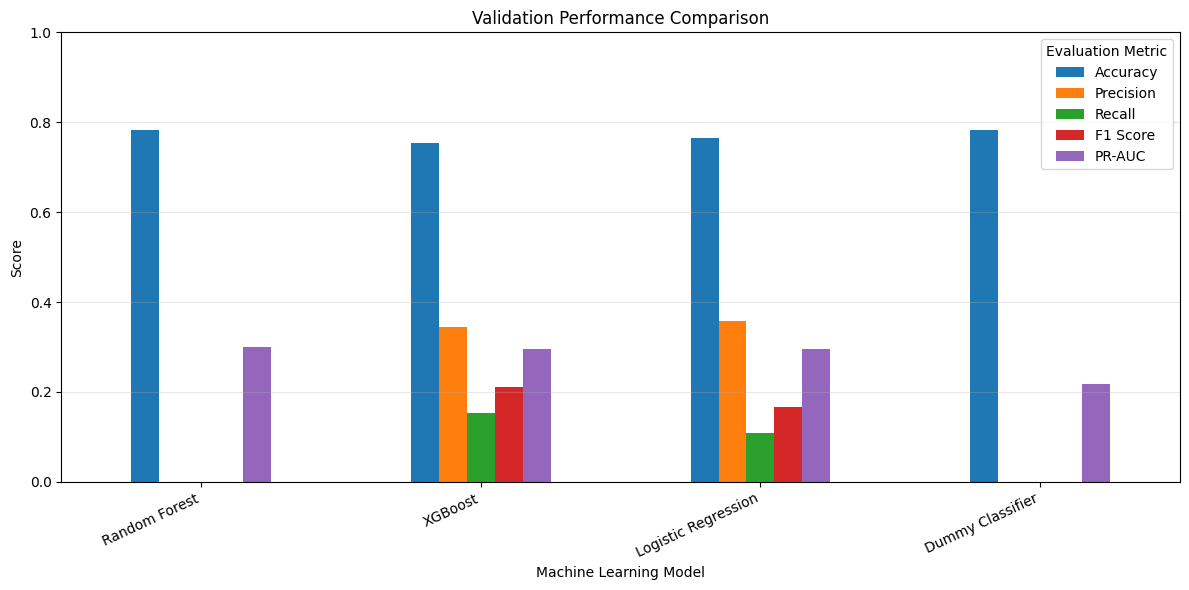

In [23]:
import matplotlib.pyplot as plt

# Compare evaluation metrics
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "PR-AUC"
]

ax = comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Validation Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.9 Precision-Recall Curve Analysis

Compare precision-recall curves to evaluate each model's ability to identify delayed flights while controlling false alarms.

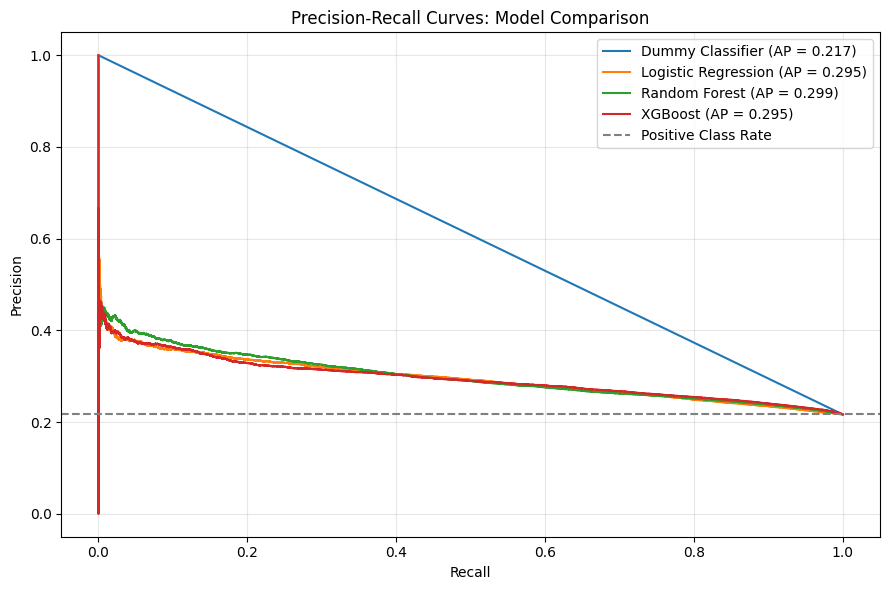

In [24]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

model_probabilities = {
    "Dummy Classifier": dummy_prob,
    "Logistic Regression": logistic_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob
}

plt.figure(figsize=(9, 6))

for name, probabilities in model_probabilities.items():
    precision, recall, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    ap = average_precision_score(y_val, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    color="gray",
    label="Positive Class Rate"
)

plt.title("Precision-Recall Curves: Model Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.10 Initial Model Performance Review

Review the initial machine learning results to identify opportunities for improvement.

The Random Forest model achieved the highest validation PR-AUC (0.2991), but its recall was zero at the default classification threshold of 0.50. XGBoost achieved a validation recall of 0.1525 and an F1-score of 0.2114.

This analysis focuses on improving the balance between precision and recall while reducing unnecessary delay alerts.

In [25]:
# Preserve initial model comparison
initial_comparison_df = comparison_df.copy()

print("INITIAL MODEL PERFORMANCE")
print("=" * 50)

display(initial_comparison_df.round(4))

print("\nInitial Best Model:")
print(initial_comparison_df.iloc[0]["Model"])

print("\nImprovement Objectives:")
print("1. Improve PR-AUC")
print("2. Improve F1-score")
print("3. Increase delay detection")
print("4. Reduce unnecessary alerts")

INITIAL MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Random Forest,0.7834,0.0000,0.0000,0.0000,0.2991
1,XGBoost,0.7536,0.3446,0.1525,0.2114,0.2953
2,Logistic Regression,0.7644,0.3570,0.1093,0.1674,0.2953
3,Dummy Classifier,0.7834,0.0000,0.0000,0.0000,0.2166



Initial Best Model:
Random Forest

Improvement Objectives:
1. Improve PR-AUC
2. Improve F1-score
3. Increase delay detection
4. Reduce unnecessary alerts


### 3.11 Random Forest Hyperparameter Tuning

Evaluate different Random Forest configurations using training and validation data. Adjust tree depth and minimum leaf size to improve predictive performance while controlling model complexity.

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score

rf_configs = [
    {"max_depth": 10, "min_samples_leaf": 20},
    {"max_depth": 20, "min_samples_leaf": 10},
    {"max_depth": 25, "min_samples_leaf": 5}
]

rf_tuning_results = []
rf_candidates = {}

for i, params in enumerate(rf_configs):

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=params["max_depth"],
            min_samples_leaf=params["min_samples_leaf"],
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_val)[:, 1]

    score = average_precision_score(
        y_val, probabilities
    )

    model_name = f"RF_Config_{i+1}"

    rf_candidates[model_name] = model

    rf_tuning_results.append({
        "Model": model_name,
        "Max Depth": params["max_depth"],
        "Min Samples Leaf": params["min_samples_leaf"],
        "PR-AUC": score
    })

rf_tuning_df = pd.DataFrame(
    rf_tuning_results
).sort_values("PR-AUC", ascending=False)

display(rf_tuning_df.round(4))

best_rf_name = rf_tuning_df.iloc[0]["Model"]
improved_rf = rf_candidates[best_rf_name]

print("Best RF Configuration:", best_rf_name)

,Model,Max Depth,Min Samples Leaf,PR-AUC
1,RF_Config_2,20,10,0.2997
2,RF_Config_3,25,5,0.2986
0,RF_Config_1,10,20,0.2969


Best RF Configuration: RF_Config_2


### 3.12 XGBoost Hyperparameter Tuning

Evaluate alternative XGBoost configurations by adjusting the number of estimators, tree depth, and learning rate. Select the configuration with the highest validation PR-AUC.

In [27]:
from xgboost import XGBClassifier

xgb_configs = [
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05},
    {"n_estimators": 400, "max_depth": 5, "learning_rate": 0.05},
    {"n_estimators": 500, "max_depth": 6, "learning_rate": 0.03}
]

xgb_tuning_results = []
xgb_candidates = {}

for i, params in enumerate(xgb_configs):

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            **params,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            subsample=0.8,
            colsample_bytree=0.8,
            n_jobs=-1,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_val)[:, 1]

    score = average_precision_score(
        y_val, probabilities
    )

    model_name = f"XGB_Config_{i+1}"

    xgb_candidates[model_name] = model

    xgb_tuning_results.append({
        "Model": model_name,
        "Estimators": params["n_estimators"],
        "Max Depth": params["max_depth"],
        "Learning Rate": params["learning_rate"],
        "PR-AUC": score
    })

xgb_tuning_df = pd.DataFrame(
    xgb_tuning_results
).sort_values("PR-AUC", ascending=False)

display(xgb_tuning_df.round(4))

best_xgb_name = xgb_tuning_df.iloc[0]["Model"]
improved_xgb = xgb_candidates[best_xgb_name]

print("Best XGBoost Configuration:", best_xgb_name)

,Model,Estimators,Max Depth,Learning Rate,PR-AUC
1,XGB_Config_2,400,5,0.05,0.2967
0,XGB_Config_1,200,4,0.05,0.2955
2,XGB_Config_3,500,6,0.03,0.2950


Best XGBoost Configuration: XGB_Config_2


### 3.13 Improved Model Performance Comparison

Compare the original and tuned machine learning models using the same validation dataset. Select the best model based on validation PR-AUC without accessing the final test set.

In [28]:
# Compare original and tuned models
candidate_models = {
    "Logistic Regression": logistic_model,
    "Original Random Forest": rf_model,
    "Original XGBoost": xgb_model,
    "Tuned Random Forest": improved_rf,
    "Tuned XGBoost": improved_xgb
}

improved_results = []
candidate_probabilities = {}

for name, model in candidate_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    candidate_probabilities[name] = probabilities

    improved_results.append(
        evaluate_model(
            name, y_val, predictions, probabilities
        )
    )

improved_comparison_df = pd.DataFrame(
    improved_results
).sort_values(
    "PR-AUC", ascending=False
).reset_index(drop=True)

display(improved_comparison_df.round(4))

improved_model_name = improved_comparison_df.iloc[0]["Model"]
improved_model = candidate_models[improved_model_name]
improved_val_prob = candidate_probabilities[improved_model_name]

print("Selected Improved Model:", improved_model_name)

,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Tuned Random Forest,0.7834,0.0000,0.0000,0.0000,0.2997
1,Original Random Forest,0.7834,0.0000,0.0000,0.0000,0.2991
2,Tuned XGBoost,0.7554,0.3502,0.1512,0.2112,0.2967
3,Original XGBoost,0.7536,0.3446,0.1525,0.2114,0.2953
4,Logistic Regression,0.7644,0.3570,0.1093,0.1674,0.2953


Selected Improved Model: Tuned Random Forest


### 3.14 Classification Threshold Optimization

Optimize the classification threshold on validation data to balance precision and recall. Select the threshold that maximizes F1-score while monitoring the percentage of flights receiving delay alerts.

Optimized Threshold: 0.2026

Improved Validation Metrics:


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Tuned Random Forest,0.4683,0.2563,0.7651,0.384,0.2997


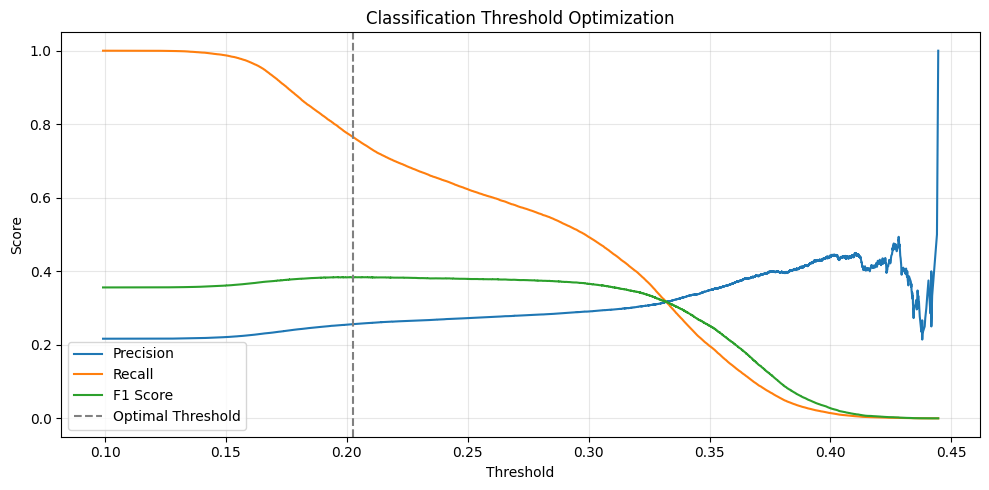

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Calculate precision and recall at all score thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, improved_val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    np.maximum(precision[:-1] + recall[:-1], 1e-12)
)

best_index = np.argmax(f1_scores)
best_improved_threshold = float(thresholds[best_index])

improved_val_pred = (
    improved_val_prob >= best_improved_threshold
).astype(int)

print(f"Optimized Threshold: {best_improved_threshold:.4f}")

print("\nImproved Validation Metrics:")
display(pd.DataFrame([
    evaluate_model(
        improved_model_name,
        y_val,
        improved_val_pred,
        improved_val_prob
    )
]).round(4))

# Plot threshold optimization
plt.figure(figsize=(10, 5))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1 Score")

plt.axvline(
    best_improved_threshold,
    linestyle="--",
    color="gray",
    label="Optimal Threshold"
)

plt.title("Classification Threshold Optimization")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.15 Initial vs. Improved Validation Performance

Compare the initial selected model with the improved model using the same validation dataset. Evaluate whether tuning improved precision, recall, F1-score, and PR-AUC.

INITIAL VS IMPROVED VALIDATION PERFORMANCE


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Initial Random Forest,0.4305,0.2497,0.8128,0.3821,0.2991
1,Tuned Random Forest,0.4683,0.2563,0.7651,0.3840,0.2997


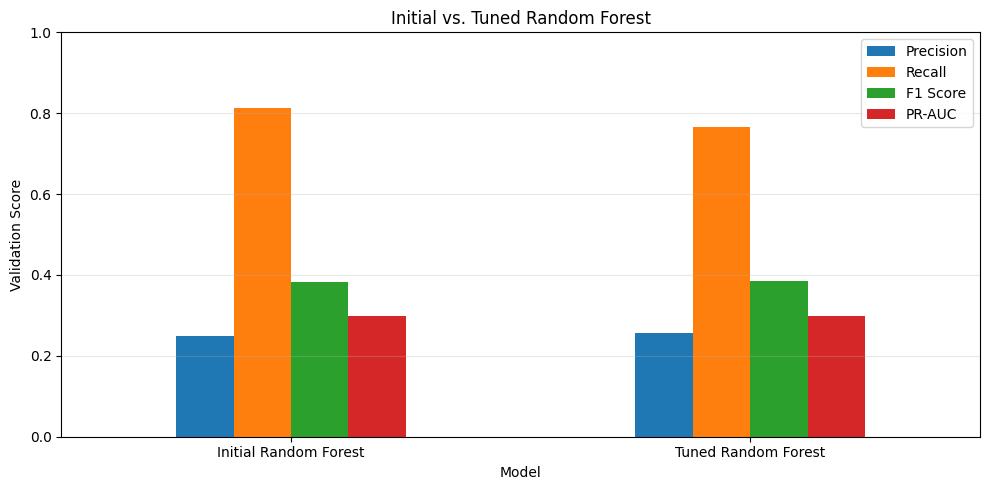

In [30]:
# Reproduce the original Random Forest validation results
original_val_prob = rf_model.predict_proba(X_val)[:, 1]

# Threshold selected from the original validation analysis
original_threshold = 0.20
original_val_pred = (
    original_val_prob >= original_threshold
).astype(int)

# Evaluate both models on the same validation sample
initial_validation_results = evaluate_model(
    "Initial Random Forest",
    y_val,
    original_val_pred,
    original_val_prob
)

improved_validation_results = evaluate_model(
    "Tuned Random Forest",
    y_val,
    improved_val_pred,
    improved_val_prob
)

validation_comparison = pd.DataFrame([
    initial_validation_results,
    improved_validation_results
])

print("INITIAL VS IMPROVED VALIDATION PERFORMANCE")
display(validation_comparison.round(4))

# Visualize performance comparison
metrics = ["Precision", "Recall", "F1 Score", "PR-AUC"]

validation_comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Initial vs. Tuned Random Forest")
plt.ylabel("Validation Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.16 Save the Improved Model

Save the selected improved model, optimized classification threshold, and validation results for reproducibility and prototype development.

In [31]:
import joblib

joblib.dump(
    improved_model,
    "/content/CIS508_Improved_Model.joblib"
)

joblib.dump(
    best_improved_threshold,
    "/content/CIS508_Improved_Threshold.joblib"
)

validation_comparison.to_csv(
    "/content/CIS508_Validation_Comparison.csv",
    index=False
)

improved_comparison_df.to_csv(
    "/content/CIS508_Improved_Model_Comparison.csv",
    index=False
)

print("Improved model and validation results saved.")

Improved model and validation results saved.


## 4. Model Evaluation and Reliability Checks

### 4.1 Select the Best Model

Select the best-performing machine learning model based on validation PR-AUC. Evaluate both predictive performance and the ability to identify delayed flights.

In [32]:
# Select the best model based on validation PR-AUC
best_model_name = comparison_df.sort_values(
    "PR-AUC", ascending=False
).iloc[0]["Model"]

trained_models = {
    "Dummy Classifier": dummy_model,
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

validation_probabilities = {
    "Dummy Classifier": dummy_prob,
    "Logistic Regression": logistic_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob
}

best_model = trained_models[best_model_name]
best_val_prob = validation_probabilities[best_model_name]

print("Selected Model:", best_model_name)

display(
    comparison_df[
        comparison_df["Model"] == best_model_name
    ].round(4)
)

Selected Model: Random Forest


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Random Forest,0.7834,0.0,0.0,0.0,0.2991


### 4.2 Classification Threshold Optimization

Evaluate different classification thresholds using validation data. Select the threshold that maximizes F1-score while considering the trade-off between missed delays and false alarms.

In [33]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.05):

    predictions = (
        best_val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_threshold = float(
    threshold_df.loc[
        threshold_df["F1 Score"].idxmax(),
        "Threshold"
    ]
)

print("Selected Threshold:", best_threshold)

display(threshold_df.round(4))

Selected Threshold: 0.2


,Threshold,Precision,Recall,F1 Score
0,0.05,0.2166,1.0000,0.3561
1,0.10,0.2166,1.0000,0.3561
2,0.15,0.2176,0.9964,0.3573
3,0.20,0.2497,0.8128,0.3821
4,0.25,0.2729,0.6200,0.3790
5,0.30,0.2970,0.4428,0.3555
6,0.35,0.3884,0.0693,0.1177
7,0.40,0.4286,0.0007,0.0015
8,0.45,0.0000,0.0000,0.0000
9,0.50,0.0000,0.0000,0.0000


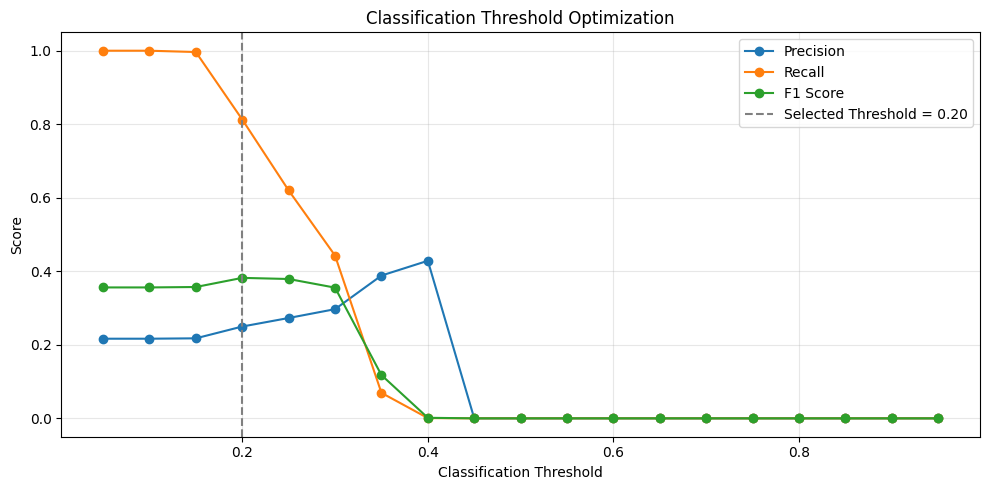

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for metric in ["Precision", "Recall", "F1 Score"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.axvline(
    best_threshold,
    linestyle="--",
    color="gray",
    label=f"Selected Threshold = {best_threshold:.2f}"
)

plt.title("Classification Threshold Optimization")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.3 Confusion Matrix Analysis

Analyze true positives, true negatives, false positives, and false negatives using the selected validation threshold.

True Negatives: 38167
False Positives: 79341
False Negatives: 6081
True Positives: 26411


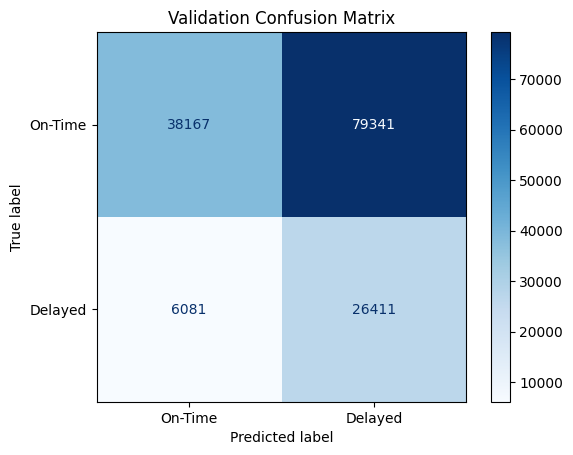

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

best_val_pred = (
    best_val_prob >= best_threshold
).astype(int)

cm = confusion_matrix(
    y_val,
    best_val_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["On-Time", "Delayed"]
).plot(cmap="Blues", values_format="d")

plt.title("Validation Confusion Matrix")
plt.show()

### 4.4 Performance by Airline

Evaluate model performance across airlines to identify differences in recall, precision, and error rates. Use a minimum sample size to avoid unreliable comparisons.

In [36]:
# Build a validation analysis dataset
val_analysis = val_sample[
    ["FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN",
     "DEST", "ARR_DEL15"]
].copy()

val_analysis["Predicted"] = best_val_pred
val_analysis["Probability"] = best_val_prob

def subgroup_metrics(group):
    actual = group["ARR_DEL15"]
    predicted = group["Predicted"]

    return pd.Series({
        "Flights": len(group),
        "Actual Delay Rate": actual.mean(),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1 Score": f1_score(
            actual, predicted, zero_division=0
        ),
        "False Positive Rate": (
            ((actual == 0) & (predicted == 1)).sum()
            / max((actual == 0).sum(), 1)
        )
    })

airline_performance = (
    val_analysis.groupby("OP_UNIQUE_CARRIER")
    .apply(subgroup_metrics, include_groups=False)
    .reset_index()
)

# Include airlines with sufficient observations
airline_performance = airline_performance[
    airline_performance["Flights"] >= 500
].sort_values("Recall")

display(airline_performance.round(4))

,OP_UNIQUE_CARRIER,Flights,Actual Delay Rate,Precision,Recall,F1 Score,False Positive Rate
3,DL,21465.0,0.1911,0.2242,0.7030,0.3400,0.5746
9,OO,18000.0,0.2271,0.2537,0.7324,0.3768,0.6332
6,MQ,6622.0,0.1860,0.2119,0.7451,0.3299,0.6336
1,AS,6999.0,0.2015,0.2151,0.7858,0.3378,0.7234
10,UA,17826.0,0.1825,0.2021,0.7864,0.3216,0.6928
8,OH,5016.0,0.2598,0.2943,0.7943,0.4295,0.6685
12,YX,7643.0,0.2261,0.2581,0.7992,0.3902,0.6710
7,NK,3012.0,0.3556,0.4233,0.8095,0.5559,0.6084
11,WN,30114.0,0.1982,0.2620,0.8224,0.3974,0.5726
5,G4,2799.0,0.2583,0.3021,0.8465,0.4453,0.6811


### 4.5 Performance by Airport

Evaluate prediction reliability across origin and destination airports. Identify locations with unusually high false positive rates or low recall.

In [37]:
# Origin airport performance
origin_performance = (
    val_analysis.groupby("ORIGIN")
    .apply(subgroup_metrics, include_groups=False)
    .reset_index()
)

origin_performance = (
    origin_performance[
        origin_performance["Flights"] >= 500
    ]
    .sort_values("Recall")
)

print("Origin Airport Performance:")
display(origin_performance.head(15).round(4))

# Destination airport performance
destination_performance = (
    val_analysis.groupby("DEST")
    .apply(subgroup_metrics, include_groups=False)
    .reset_index()
)

destination_performance = (
    destination_performance[
        destination_performance["Flights"] >= 500
    ]
    .sort_values("Recall")
)

print("Destination Airport Performance:")
display(destination_performance.head(15).round(4))

Origin Airport Performance:


,ORIGIN,Flights,Actual Delay Rate,Precision,Recall,F1 Score,False Positive Rate
77,CVG,693.0,0.2121,0.2228,0.5850,0.3227,0.5495
68,CMH,989.0,0.1658,0.1980,0.6098,0.2990,0.4909
224,MSP,2319.0,0.2393,0.2553,0.6559,0.3675,0.6020
206,MEM,510.0,0.1882,0.2327,0.6667,0.3450,0.5097
51,BUR,656.0,0.1418,0.1632,0.6774,0.2630,0.5737
253,PIT,860.0,0.1791,0.2500,0.6818,0.3659,0.4462
244,PDX,1274.0,0.1358,0.1429,0.6879,0.2366,0.6485
305,SLC,2575.0,0.1483,0.1655,0.6963,0.2675,0.6115
93,DTW,2591.0,0.2771,0.3053,0.7117,0.4273,0.6209
230,OGG,562.0,0.2295,0.2371,0.7132,0.3559,0.6836


Destination Airport Performance:


,DEST,Flights,Actual Delay Rate,Precision,Recall,F1 Score,False Positive Rate
230,OGG,589.0,0.2003,0.2491,0.6186,0.3552,0.4671
17,ATL,6650.0,0.1771,0.2227,0.6604,0.3330,0.4963
305,SLC,2698.0,0.1672,0.2105,0.6763,0.3211,0.5091
86,DEN,6831.0,0.1840,0.2153,0.7049,0.3299,0.5793
224,MSP,2230.0,0.2036,0.2449,0.7093,0.3640,0.5591
145,HNL,1369.0,0.2257,0.2887,0.7184,0.4119,0.5160
93,DTW,2586.0,0.2746,0.3107,0.7268,0.4353,0.6103
293,SEA,3276.0,0.1798,0.2023,0.7317,0.3169,0.6327
155,IAH,2642.0,0.1540,0.1841,0.7543,0.2959,0.6089
67,CLT,3722.0,0.1848,0.2221,0.7616,0.3439,0.6048


### 4.6 Monthly Performance and Reliability

Compare validation performance across months to identify temporal variation and possible model drift.

,YEAR_MONTH,Flights,Actual Delay Rate,Precision,Recall,F1 Score,False Positive Rate
0,2026-01,48279.0,0.2085,0.2355,0.7876,0.3626,0.6735
1,2026-02,46294.0,0.1967,0.2286,0.8154,0.3571,0.6735
2,2026-03,55427.0,0.2403,0.2791,0.8302,0.4178,0.6782


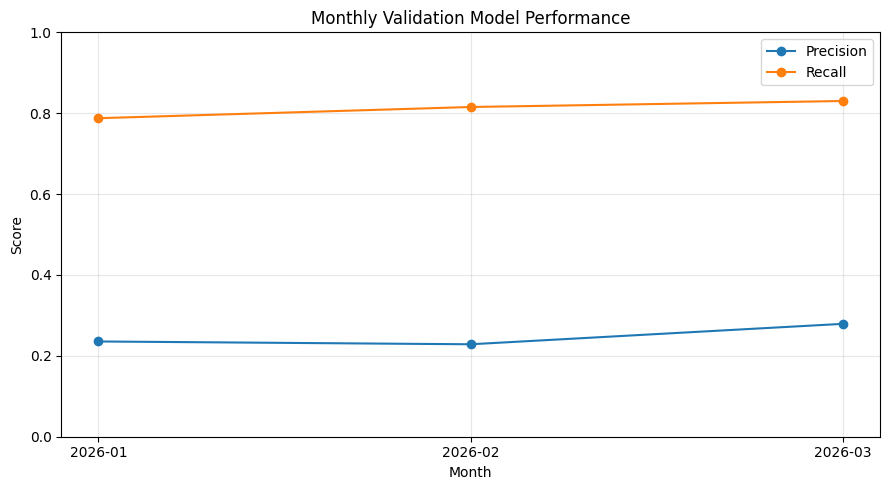

In [38]:
# Create monthly validation groups
val_analysis["YEAR_MONTH"] = (
    pd.to_datetime(val_analysis["FL_DATE"])
    .dt.to_period("M")
    .astype(str)
)

monthly_performance = (
    val_analysis.groupby("YEAR_MONTH")
    .apply(subgroup_metrics, include_groups=False)
    .reset_index()
)

display(monthly_performance.round(4))

# Visualize monthly precision and recall
plt.figure(figsize=(9, 5))

plt.plot(
    monthly_performance["YEAR_MONTH"],
    monthly_performance["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    monthly_performance["YEAR_MONTH"],
    monthly_performance["Recall"],
    marker="o",
    label="Recall"
)

plt.title("Monthly Validation Model Performance")
plt.xlabel("Month")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.7 Probability Calibration Analysis

Assess whether predicted arrival-delay probabilities correspond to observed delay frequencies. This diagnostic evaluates calibration without modifying the trained model.

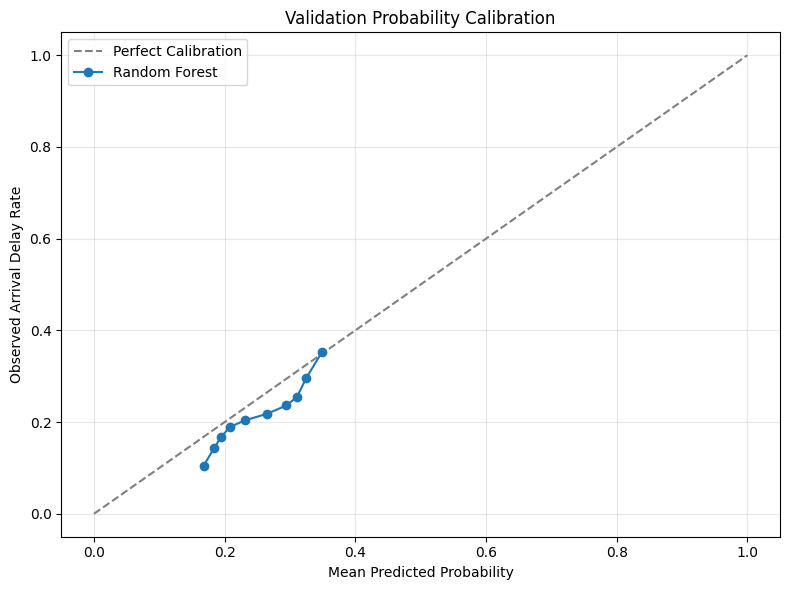

Validation Brier Score: 0.1665


In [39]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fraction_of_positives, mean_predicted_value = (
    calibration_curve(
        y_val,
        best_val_prob,
        n_bins=10,
        strategy="quantile"
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label=best_model_name
)

plt.title("Validation Probability Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Arrival Delay Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Validation Brier Score:",
    round(brier_score_loss(y_val, best_val_prob), 4)
)

### 4.8 Final Test Set Evaluation

Evaluate the selected model on the untouched April–May 2026 test set. Use the model and classification threshold selected from validation data without additional tuning.

Final Test Set Evaluation


,Model,Threshold,Test Records,Accuracy,Precision,Recall,F1 Score,PR-AUC,Brier Score
0,Random Forest,0.2,1195552,0.4349,0.2478,0.8425,0.383,0.3016,0.1606


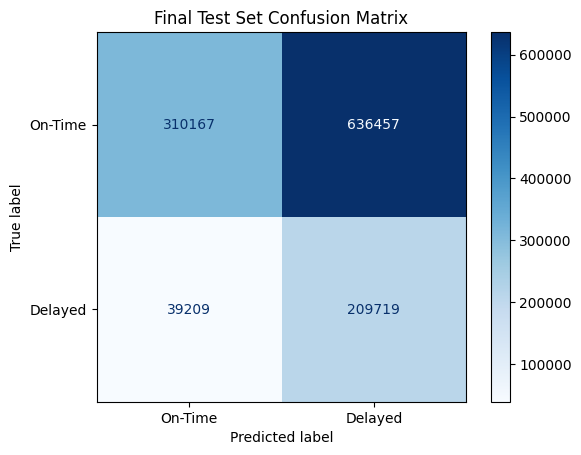

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    brier_score_loss
)

# Prepare the untouched test set
X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Generate test probabilities with the frozen model
test_prob = best_model.predict_proba(X_test)[:, 1]

# Apply the frozen validation threshold
test_pred = (
    test_prob >= best_threshold
).astype(int)

# Calculate final evaluation metrics
final_results = {
    "Model": best_model_name,
    "Threshold": best_threshold,
    "Test Records": len(y_test),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "PR-AUC": average_precision_score(
        y_test, test_prob
    ),
    "Brier Score": brier_score_loss(
        y_test, test_prob
    )
}

final_results_df = pd.DataFrame([final_results])

print("Final Test Set Evaluation")
display(final_results_df.round(4))

# Display final confusion matrix
final_cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["On-Time", "Delayed"]
).plot(cmap="Blues", values_format="d")

plt.title("Final Test Set Confusion Matrix")
plt.show()

### 4.9 Final Evaluation Summary

Summarize final model performance, prediction reliability, and business implications. Discuss the trade-off between missed arrival delays and unnecessary warnings, along with limitations and opportunities for improvement.

In [41]:
# Summarize final model results
print("=" * 50)
print("FLIGHT ARRIVAL DELAY PREDICTION")
print("FINAL MODEL EVALUATION")
print("=" * 50)

print(f"Selected Model: {best_model_name}")
print(f"Classification Threshold: {best_threshold:.2f}")
print(f"Final Test Records: {len(y_test):,}")

print("\nPerformance Metrics")
print("-" * 30)

for metric in [
    "Accuracy", "Precision", "Recall",
    "F1 Score", "PR-AUC", "Brier Score"
]:
    print(f"{metric}: {final_results[metric]:.4f}")

tn, fp, fn, tp = final_cm.ravel()

print("\nPrediction Outcomes")
print("-" * 30)
print(f"True Positives: {tp:,}")
print(f"True Negatives: {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")

# Export final evaluation results
final_results_df.to_csv(
    "/content/CIS508_Final_Model_Results.csv",
    index=False
)

comparison_df.to_csv(
    "/content/CIS508_Model_Comparison.csv",
    index=False
)

print("\nEvaluation results exported successfully.")

FLIGHT ARRIVAL DELAY PREDICTION
FINAL MODEL EVALUATION
Selected Model: Random Forest
Classification Threshold: 0.20
Final Test Records: 1,195,552

Performance Metrics
------------------------------
Accuracy: 0.4349
Precision: 0.2478
Recall: 0.8425
F1 Score: 0.3830
PR-AUC: 0.3016
Brier Score: 0.1606

Prediction Outcomes
------------------------------
True Positives: 209,719
True Negatives: 310,167
False Positives: 636,457
False Negatives: 39,209

Evaluation results exported successfully.


## 5. Flight Arrival Delay Prediction Prototype

### 5.1 Prototype Overview

Develop an interactive flight arrival delay prediction prototype using the selected machine learning model.

The prototype accepts flight information available before departure, applies the same preprocessing pipeline used during training, and estimates the probability of arriving at least 15 minutes late.

Prediction results are classified into Low, Medium, or High Risk to support proactive flight monitoring and operational decision-making.

### 5.2 Define Risk Levels

Convert predicted arrival-delay probabilities into three risk categories. The initial risk categories are illustrative and should be reviewed against the validation data before operational use.

In [42]:
def classify_risk(probability):
    """
    Classify predicted arrival-delay probability
    into Low, Medium, or High Risk.
    """
    if probability < 0.20:
        return "Low Risk"
    elif probability < 0.40:
        return "Medium Risk"
    else:
        return "High Risk"


# Example only: these are not actual model predictions
for probability in [0.12, 0.32, 0.65]:
    print(
        f"Probability: {probability:.0%} | "
        f"Risk Level: {classify_risk(probability)}"
    )

Probability: 12% | Risk Level: Low Risk
Probability: 32% | Risk Level: Medium Risk
Probability: 65% | Risk Level: High Risk


### 5.3 Flight Arrival Delay Prediction Function

Create a reusable prediction function that converts user-provided flight information into the model's required features and generates an estimated arrival-delay probability.

In [43]:

def predict_flight_delay(
    carrier,
    origin,
    destination,
    flight_date,
    scheduled_departure,
    scheduled_arrival,
    scheduled_elapsed_time,
    distance
):
    """
    Predict whether a scheduled flight will arrive
    at least 15 minutes late using the improved model.
    """

    # Validate flight date
    flight_date = pd.to_datetime(flight_date)

    if pd.isna(flight_date):
        raise ValueError("Please enter a valid flight date.")

    # Validate scheduled departure and arrival times
    dep_time = int(scheduled_departure)
    arr_time = int(scheduled_arrival)

    def valid_time(value):
        hour = value // 100
        minute = value % 100

        return (
            0 <= value <= 2359
            and 0 <= hour <= 23
            and 0 <= minute <= 59
        )

    if not valid_time(dep_time) or not valid_time(arr_time):
        raise ValueError(
            "Scheduled times must be valid HHMM values."
        )

    # Validate flight duration and distance
    if scheduled_elapsed_time <= 0 or distance <= 0:
        raise ValueError(
            "Flight duration and distance must be positive."
        )

    # Prepare flight information
    flight_input = pd.DataFrame([{
        "OP_UNIQUE_CARRIER": str(carrier).strip().upper(),
        "ORIGIN": str(origin).strip().upper(),
        "DEST": str(destination).strip().upper(),
        "MONTH": flight_date.month,
        "DAY_OF_MONTH": flight_date.day,
        "DAY_OF_WEEK": flight_date.dayofweek,
        "DEP_HOUR": dep_time // 100,
        "ARR_HOUR": arr_time // 100,
        "CRS_ELAPSED_TIME": float(scheduled_elapsed_time),
        "DISTANCE": float(distance)
    }])

    # Match the training feature structure
    flight_input = flight_input[feature_columns]

    # Generate probability using the improved model
    probability = float(
        improved_model.predict_proba(flight_input)[0, 1]
    )

    # Assign a risk category
    risk_level = classify_risk(probability)

    # Apply the optimized validation threshold
    alert = probability >= best_improved_threshold

    # Return prediction results
    return {
        "Arrival Delay Probability": probability,
        "Risk Level": risk_level,
        "Delay Alert": "Yes" if alert else "No",
        "Model": improved_model_name
    }


### 5.4 Interactive Flight Prediction Interface

Build a user-friendly interface allowing users to enter flight details and generate arrival-delay predictions without modifying Python code.

In [51]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from datetime import date

# Available airlines and airports from training data
carrier_options = sorted(
    train_df["OP_UNIQUE_CARRIER"].dropna().unique().tolist()
)

origin_options = sorted(
    train_df["ORIGIN"].dropna().unique().tolist()
)

destination_options = sorted(
    train_df["DEST"].dropna().unique().tolist()
)

# Input widgets
carrier_widget = widgets.Dropdown(
    options=carrier_options,
    description="Airline:",
    style={"description_width": "130px"}
)

origin_widget = widgets.Dropdown(
    options=origin_options,
    description="Origin:",
    style={"description_width": "130px"}
)

destination_widget = widgets.Dropdown(
    options=destination_options,
    description="Destination:",
    style={"description_width": "130px"}
)

date_widget = widgets.DatePicker(
    description="Flight Date:",
    value=date(2026, 5, 15),
    style={"description_width": "130px"}
)

departure_widget = widgets.IntText(
    value=800,
    description="Departure (HHMM):",
    style={"description_width": "130px"}
)

arrival_widget = widgets.IntText(
    value=1100,
    description="Arrival (HHMM):",
    style={"description_width": "130px"}
)

duration_widget = widgets.FloatText(
    value=180,
    description="Duration (min):",
    style={"description_width": "130px"}
)

distance_widget = widgets.FloatText(
    value=1000,
    description="Distance (miles):",
    style={"description_width": "130px"}
)

predict_button = widgets.Button(
    description="Predict Arrival Delay",
    button_style="primary",
    icon="plane"
)

output_widget = widgets.Output()

# Prediction button callback
def on_predict_clicked(button):
    with output_widget:
        clear_output(wait=True)

        try:
            if date_widget.value is None:
                raise ValueError("Please select a flight date.")

            result = predict_flight_delay(
                carrier=carrier_widget.value,
                origin=origin_widget.value,
                destination=destination_widget.value,
                flight_date=date_widget.value,
                scheduled_departure=departure_widget.value,
                scheduled_arrival=arrival_widget.value,
                scheduled_elapsed_time=duration_widget.value,
                distance=distance_widget.value
            )

            print("=" * 45)
            print("FLIGHT ARRIVAL DELAY PREDICTION")
            print("=" * 45)

            print(
                f"Route: {origin_widget.value} "
                f"to {destination_widget.value}"
            )
            print(f"Airline: {carrier_widget.value}")
            print(f"Flight Date: {date_widget.value}")

            print("\nPREDICTION RESULTS")
            print("-" * 45)

            print(
                "Estimated Delay Probability: "
                f"{result['Arrival Delay Probability']:.2%}"
            )

            print(f"Risk Level: {result['Risk Level']}")
            print(f"Delay Alert: {result['Delay Alert']}")
            print(f"Model: {result['Model']}")

            print("\nNote: Predictions are estimates,")
            print("not guaranteed flight outcomes.")

        except Exception as error:
            print("Prediction Error:", str(error))

predict_button.on_click(on_predict_clicked)

# Display interactive interface
display(
    widgets.VBox([
        widgets.HTML("<h3>Flight Arrival Delay Predictor</h3>"),
        carrier_widget,
        origin_widget,
        destination_widget,
        date_widget,
        departure_widget,
        arrival_widget,
        duration_widget,
        distance_widget,
        predict_button,
        output_widget
    ])
)

### 5.5 Prototype Validation and Testing

Verify that the prediction function generates valid probabilities and risk categories. Check input validation, preprocessing consistency, and prediction reliability.

In [45]:
### 5.5 Prototype Validation and Testing

# Test the improved model using an existing training record
# This is a functional test, not an independent evaluation

example = train_df.iloc[0]

example_input = example[feature_columns].to_frame().T

for column in numerical_features:
    example_input[column] = pd.to_numeric(
        example_input[column]
    )

# Use the improved model
example_probability = float(
    improved_model.predict_proba(example_input)[0, 1]
)

example_risk = classify_risk(example_probability)
example_alert = (
    "Yes" if example_probability >= best_improved_threshold
    else "No"
)

assert 0 <= example_probability <= 1
assert example_risk in [
    "Low Risk", "Medium Risk", "High Risk"
]

print("Prototype Functional Test: PASSED")
print(f"Estimated Probability: {example_probability:.2%}")
print(f"Risk Level: {example_risk}")
print(f"Delay Alert: {example_alert}")
print(f"Selected Model: {improved_model_name}")

Prototype Functional Test: PASSED
Estimated Probability: 21.49%
Risk Level: Medium Risk
Delay Alert: Yes
Selected Model: Tuned Random Forest


### 5.6 Prototype Limitations and Responsible Use

The prototype estimates the probability that a scheduled U.S. flight will arrive at least 15 minutes late based on historical flight characteristics.

The model uses scheduled flight information available before departure and does not incorporate real-time weather, air traffic control decisions, aircraft maintenance, or other unexpected operational disruptions.

Canceled and diverted flights are outside the prediction target.

Predictions may be less reliable for routes, schedules, and operating conditions that differ from the training data. Risk categories are illustrative and are not equivalent to guaranteed operational outcomes.

The prototype is intended to support human decision-making, not automatically cancel, delay, or reroute flights. Final operational decisions remain under human supervision.

## 6. Final Results and Business Recommendations

### 6.1 Final Model Performance Summary

The Tuned Random Forest was selected as the improved model based on validation PR-AUC. It achieved a validation PR-AUC of 0.2997, compared with 0.2991 for the original Random Forest.

At the optimized threshold of 0.2026, the tuned model achieved 25.63% precision, 76.51% recall, and an F1-score of 0.3840. These results indicate a modest improvement in precision and F1-score, accompanied by a reduction in recall.

The original Random Forest achieved 84.25% recall, 24.78% precision, and a PR-AUC of 0.3016 on the April–May 2026 test set.

The tuned model has only been evaluated on validation data. Its results should not be presented as independent test performance.

In [46]:
print("INITIAL TEST SET RESULTS")
display(final_results_df.round(4))

print("\nINITIAL VS. TUNED MODEL - VALIDATION RESULTS")
display(validation_comparison.round(4))

print("\nSelected Tuned Model:", improved_model_name)
print(f"Optimized Threshold: {best_improved_threshold:.4f}")

INITIAL TEST SET RESULTS


,Model,Threshold,Test Records,Accuracy,Precision,Recall,F1 Score,PR-AUC,Brier Score
0,Random Forest,0.2,1195552,0.4349,0.2478,0.8425,0.383,0.3016,0.1606



INITIAL VS. TUNED MODEL - VALIDATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Initial Random Forest,0.4305,0.2497,0.8128,0.3821,0.2991
1,Tuned Random Forest,0.4683,0.2563,0.7651,0.3840,0.2997



Selected Tuned Model: Tuned Random Forest
Optimized Threshold: 0.2026


### 6.2 Business Impact Analysis

The tuned Random Forest reduced false delay alerts from 79,341 to 72,127 on the 150,000-flight validation sample, a reduction of 7,214 unnecessary warnings.

Precision increased from 24.97% to 25.63%, while the alert rate decreased from 70.50% to 64.66%.

However, the number of correctly detected delayed flights decreased from 26,411 to 24,860. This represents a trade-off between reducing unnecessary alerts and identifying actual delays.

These results suggest that the tuned model could reduce monitoring workload, but the lower recall may cause more delayed flights to be missed.

In [47]:
### 6.2 Business Impact Analysis

from sklearn.metrics import confusion_matrix
import pandas as pd

# Initial model validation confusion matrix
initial_cm = confusion_matrix(
    y_val,
    original_val_pred,
    labels=[0, 1]
)

# Tuned model validation confusion matrix
improved_cm = confusion_matrix(
    y_val,
    improved_val_pred,
    labels=[0, 1]
)

def calculate_business_impact(model_name, cm):
    tn, fp, fn, tp = cm.ravel()

    return {
        "Model": model_name,
        "Detected Delays": tp,
        "Missed Delays": fn,
        "False Alerts": fp,
        "Recall": tp / max(tp + fn, 1),
        "Precision": tp / max(tp + fp, 1),
        "Alert Rate": (tp + fp) / cm.sum()
    }

business_impact_df = pd.DataFrame([
    calculate_business_impact(
        "Initial Random Forest", initial_cm
    ),
    calculate_business_impact(
        "Tuned Random Forest", improved_cm
    )
])

print("VALIDATION BUSINESS IMPACT COMPARISON")
display(business_impact_df.round(4))

initial = business_impact_df.iloc[0]
improved = business_impact_df.iloc[1]

print(
    "\nFalse Alerts Reduced:",
    f"{initial['False Alerts'] - improved['False Alerts']:,.0f}"
)

print(
    "Additional Missed Delays:",
    f"{improved['Missed Delays'] - initial['Missed Delays']:,.0f}"
)

print(
    "Alert Rate Reduction:",
    f"{(initial['Alert Rate'] - improved['Alert Rate'])*100:.2f}",
    "percentage points"
)

VALIDATION BUSINESS IMPACT COMPARISON


,Model,Detected Delays,Missed Delays,False Alerts,Recall,Precision,Alert Rate
0,Initial Random Forest,26411,6081,79341,0.8128,0.2497,0.7050
1,Tuned Random Forest,24860,7632,72127,0.7651,0.2563,0.6466



False Alerts Reduced: 7,214
Additional Missed Delays: 1,551
Alert Rate Reduction: 5.84 percentage points


### 6.3 Key Findings and Limitations

The analysis demonstrates that scheduled flight information provides some predictive value for identifying arrival delays. Both the original and tuned Random Forest models achieved higher PR-AUC scores than the majority-class baseline.

Hyperparameter tuning slightly improved precision, F1-score, and PR-AUC. However, the tuned model also showed lower recall, indicating that fewer false alerts came at the cost of missing additional delayed flights.

The models were trained using a sample of 300,000 flights rather than the entire training dataset. In addition, the prediction features do not include real-time weather forecasts, air traffic congestion, aircraft rotations, or unexpected operational disruptions.

Canceled and diverted flights were excluded from the prediction target. Consequently, the model does not estimate the risk of these disruptions.

The tuned model requires independent evaluation on new future flight data before operational deployment.

### 6.4 Final Business Recommendations and Conclusion

The flight arrival delay prediction system shows potential as a decision-support tool for airline operations teams and travelers.

The model can estimate arrival-delay risk before departure, helping users identify flights that may require additional monitoring or contingency planning.

However, the current results reveal an important trade-off between detecting delayed flights and generating unnecessary warnings. The tuned Random Forest reduces false alerts but misses more actual delays than the initial model.

Future improvements should focus on incorporating additional predeparture information, including weather forecasts, airport congestion indicators, and historical route performance.

Before implementation, the model should be evaluated using new independent data, and classification thresholds should be selected according to operational costs and business priorities.

Overall, the project demonstrates the feasibility of applying machine learning to flight arrival-delay prediction while highlighting the importance of model reliability, practical evaluation, and human oversight.